<a href="https://colab.research.google.com/github/T1toh/30Days_of_SQL/blob/main/MODULE_4_%7C_LESSON_2_Advanced_Volatility_Modeling.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **CAPSTONE REVIEW**

## MODULE 4 | LESSON 2: Advanced Volatility Modeling

| | |
|:---|:---|
|**Reading Time** | 4h |
|**Prior Knowledge** | Black-Scholes model, stochastic calculus, PDEs, time series analysis, GARCH models, option pricing |
|**Keywords** | stochastic volatility, Heston model, local volatility, CEV model, volatility surfaces, implied volatility, variance swaps, VIX, jump-diffusion, calibration, state space models |

---

## **Introduction**

Volatility is the ghost in the machine – the one parameter in Black-Scholes that everyone knows is wrong, yet everyone still uses.

Think about it. The formula assumes constant volatility. Markets crash. Volatility explodes. Yet tomorrow morning, thousands of traders will still quote option prices in "vol" terms. This isn't stupidity – it's pragmatism at its finest. The question is: can we do better?

In this lesson, we'll discover that the answer is a resounding yes. We'll explore models where volatility itself becomes a living, breathing random process (why should asset prices have all the fun?). We'll see how a single equation by Bruno Dupire turned the entire volatility modeling world upside down in 1994. And we'll learn why volatility has evolved from a mere parameter into an asset class worth billions.

But here's the catch: every solution creates new problems. Stochastic volatility models are elegant but hard to calibrate. Local volatility models fit the market perfectly today but may fail spectacularly tomorrow. Jump-diffusion models capture market crashes but introduce parameter instability. It pays to understand not just the mathematics, but the trade-offs.

## **1. Stochastic Volatility Models Using State Space Representations**

For decades, practitioners knew that volatility wasn't constant – just look at any financial time series. The real question was what to do about it.

### **1.1 The Heston Model Framework**

Steven Heston's 1993 model was like discovering that the Earth orbits the Sun, not the other way around. Instead of forcing volatility to be constant, why not let it evolve stochastically? The mathematics are deceptively simple:

$$dS_t = \mu S_t dt + \sqrt{\nu_t} S_t dW_t^S$$

$$d\nu_t = \kappa(\theta - \nu_t)dt + \sigma_\nu \sqrt{\nu_t} dW_t^{\nu}$$

Notice something clever here. Heston uses variance $\nu_t$, not volatility. Why? Because variance can't go negative (try taking the square root of a negative number in your portfolio calculations). The mean reversion term $\kappa(\theta - \nu_t)$ acts like a rubber band – stretch variance too far from its long-term level $\theta$, and it snaps back.

But the real magic happens with correlation. Set $\rho < 0$ between the two Brownian motions, and suddenly your model generates volatility skews for free. No calibration gymnastics required. When stocks fall, volatility rises – exactly what we observe in markets. This isn't coincidence; it's the leverage effect in action (companies become riskier as their equity value shrinks relative to debt).

It pays to examine the square root term $\sqrt{\nu_t}$ in the variance equation. This ensures variance stays positive – but only if you're careful. Discretize carelessly, and your variance can still go negative, leading to those embarrassing 'complex volatility' errors that crash trading systems at 3 AM – a surprisingly common occurrence in production systems.

### **1.2 State Space Representation and Filtering**

Here's where things get philosophically interesting. We can observe stock prices. We can't observe volatility. It's like trying to measure wind speed by watching leaves – you see the effect, not the cause.

State space models formalize this hidden-variable problem:
- **State equation**: How volatility evolves (unobserved)
- **Observation equation**: How prices depend on volatility (observed)

After discretization, Heston becomes:

$$\nu_{t+1} = \nu_t + \kappa(\theta - \nu_t)\Delta t + \sigma_\nu \sqrt{\nu_t \Delta t} \epsilon_t^{\nu}$$

$$r_{t+1} = \mu \Delta t + \sqrt{\nu_t \Delta t} \epsilon_t^S$$

Now comes the trillion-dollar question: given only the returns $r_t$, how do we infer the hidden volatility states $\nu_t$? (Hint: if this were easy, volatility trading wouldn't be profitable.)

The Kalman filter would be perfect – if only our model were linear. That pesky square root ruins everything. So we turn to approximations: Extended Kalman Filters that linearize locally, or particle filters that use brute-force Monte Carlo. Neither is perfect. Both are expensive. Welcome to real-world finance.

### **1.3 Parameter Estimation and Model Implementation**

Estimating Heston parameters is where theory meets reality, and reality usually wins. The likelihood function? Intractable. The data? Noisy. The optimization? Riddled with local minima.

Consider your options (pun intended):
1. **Maximum likelihood via filtering**: Theoretically optimal, computationally brutal
2. **Method of moments**: Quick and dirty, emphasis on dirty
3. **Option price calibration**: Market-consistent but unstable

Note the Feller condition: $2\kappa\theta > \sigma_\nu^2$. Violate this, and your variance process can hit zero and get stuck. It's like a ball rolling in a bowl that's too shallow – once it reaches the rim, it escapes and never returns to the center. Smart practitioners add a small buffer, because mathematical boundaries and numerical precision don't always play nicely.

## **2. Local Volatility Models**

Stochastic volatility models are intellectually satisfying. But what if you're a trader who needs to match market prices exactly, right now? Enter local volatility – the engineering solution to an academic problem.

### **2.1 The Dupire Framework**

Bruno Dupire's 1994 insight was breathtaking in its simplicity. If option prices are observable for all strikes and maturities (a big if), then there exists exactly one volatility function $\sigma(S,t)$ consistent with these prices. Even better, you can compute it:

$$\sigma^2(K,T) = \frac{\frac{\partial C}{\partial T} + rK\frac{\partial C}{\partial K}}{\frac{1}{2}K^2\frac{\partial^2 C}{\partial K^2}}$$

This formula is like a magic decoder ring for option markets. Feed in option prices, extract local volatilities. No parameters to estimate. No model risk. Pure arbitrage-free consistency – at least in theory.

But wait – there's always a but. The formula requires derivatives of option prices. Have you ever tried to differentiate noisy market data? It's like trying to hear a whisper in a hurricane. Small errors in prices become massive errors in volatilities. Suddenly, that parameter-free model doesn't look so attractive.

### **2.2 The CEV Model**

Sometimes you want structure without going full Black-Scholes. The CEV model offers a middle ground:

$$dS_t = \mu S_t dt + \sigma S_t^{\beta/2} dW_t$$

One parameter, $\beta$, controls everything. Set $\beta = 2$ and you're back in Black-Scholes land – familiar territory, but missing the richness of real market dynamics.. Set $\beta < 2$ and volatility decreases as prices rise – perfect for equities. The leverage effect emerges naturally, without correlation parameters or hidden states.

Why does this work? Think about it. As stock prices fall, the company's leverage increases (same debt, less equity value). Higher leverage means higher volatility. The CEV model captures this mechanically through the power term $S_t^{\beta/2}$. Sometimes the best models are the simplest – though this philosophy often conflicts with the complexity demanded by structured product markets.

### **2.3 Calibration and Implementation Challenges**

Implementing local volatility is where practitioners earn their keep. The Dupire formula looks elegant on paper. In practice? You're trying to extract second derivatives from prices quoted in sixteenths with five-cent bid-ask spreads.

Consider the workflow:
1. Collect option prices (easy)
2. Interpolate a smooth surface (hard)
3. Compute derivatives (harder)
4. Ensure no arbitrage (hardest)

Each step compounds errors from the previous one. It's like a game of telephone where the message is a partial differential equation. By the time you get your local volatilities, they might bear little resemblance to market reality.

Smart practitioners use every trick in the book. Smoothing splines (but not too smooth). Arbitrage constraints (but not too rigid). Regularization (but not too much). It's more art than science – which is why good volatility traders are worth their weight in gold (or at least in vega).

## **3. Volatility Surfaces and Calibration**

The volatility surface is the Rosetta Stone of derivatives markets – decode it correctly, and you understand how the market prices risk. Misread it, and you'll blow up your book faster than you can say "pin risk."

### **3.1 Constructing the Implied Volatility Surface**

Here's a simple exercise that breaks students' brains: take a Black-Scholes formula, plug in a market option price, and solve for volatility. Congratulations – you've just computed an implied volatility. Now do it for every strike and expiry. Plot the results. If Black-Scholes were correct, you'd see a flat plane. Instead, you see curves, smiles, and smirks. The model is wrong, yet we keep using it. (Why? Because a standardized framework, even if imperfect, provides a common language for market participants.)

The surface reveals market psychology:
- **Downside skew**: Traders pay more for crash protection
- **Volatility term structure**: Near-term uncertainty vs. long-term mean reversion
- **Smile dynamics**: How skew changes as expiry approaches

Each feature tells a story. The 1987 crash created permanent downside skew in equity markets – traders never forgot Black Monday. Currency pairs show symmetric smiles – either currency could strengthen. Commodity smiles often flip to "frowns" – upside risk from supply shocks.

### **3.2 Calibration Methodologies**

Model calibration is optimization with attitude. You want to minimize:

$$\min_{\Theta} \sum_{i=1}^{N} w_i \left( C_i^{model}(\Theta) - C_i^{market} \right)^2$$

Looks simple, right? Now try it with a Heston model. Each function evaluation requires solving PDEs or running Monte Carlo. The objective function has more local minima than a mountain range. And tomorrow's calibration better be consistent with today's, or your risk numbers are meaningless.

It pays to think about regularization. Add a penalty term:

$$\min_{\Theta} \sum_{i=1}^{N} w_i \left( C_i^{model}(\Theta) - C_i^{market} \right)^2 + \lambda ||\Theta - \Theta_0||^2$$

This says "fit the market, but don't go crazy." The parameter $\lambda$ controls the trade-off. Too small, and parameters jump around daily. Too large, and you miss important market shifts. Like tuning a precision instrument, you need exactly the right balance – too far in either direction and your calibration becomes either unstable or insensitive.

### **3.3 Interpolation and Extrapolation**

Markets give you points. You need a surface. Interpolation fills the gaps, but extrapolation is where fortunes are made (and lost).

Consider your arsenal:
- **Parametric models**: SABR for swaptions, SVI for equities
- **Splines**: Smooth but potentially oscillatory
- **Kernel methods**: Flexible but data-hungry

Each has its place. SABR works beautifully for swaptions because the model matches market dynamics. Try it on equities and watch it fail spectacularly. Splines give smooth surfaces but can create arbitrage opportunities between strikes. Kernel methods adapt to local features but struggle in the wings where data is sparse (and where tail risk lurks).

The dirty secret? Most practitioners use different methods for different purposes: one surface for pricing, another for risk management, a third for accounting. While intellectually unsatisfying, this multiplicity reflects the different requirements of each application. Perfect consistency is the enemy of robustness.

In Black‑Scholes every option—regardless of strike or maturity—shares the same volatility. Real markets disagree: deep‑out‑of‑the‑money puts command rich premia, and the skew itself flattens as time to expiry increases. The Gatheral‑Jacquier SSVI formula captures these two empirical laws with just four numbers:
$\alpha$ controls the overall level (ATM variance grows $ \approx \alpha T$); $\eta$ and $\gamma$ determine how quickly the wings fall away as maturity lengthens; ρ gives the direction and steepness of the skew. In the short script below we plug a single parameter set into the closed-form SSVI surface, lay it on top of a flat Black-Scholes surface, and visualise the difference in one shot—no optimisation, no data fitting, just the algebra.

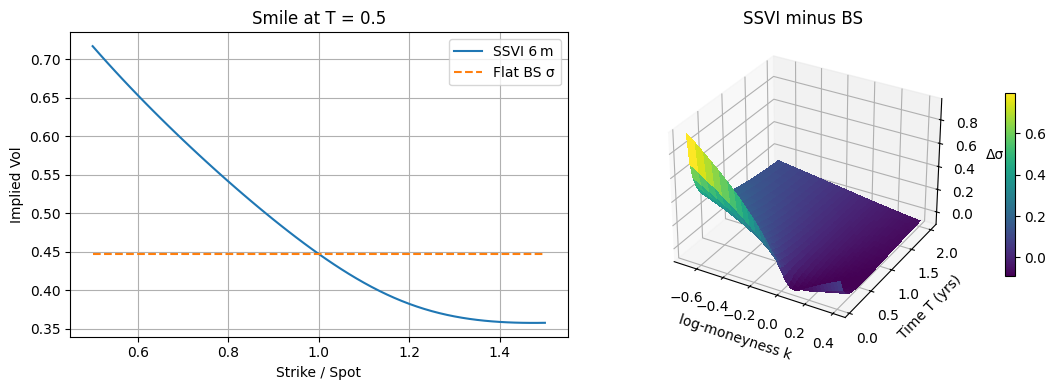

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D     # 3‑D surf plots

# SSVI (Gatheral–Jacquier 2014): total variance w(k,T)
def ssvi_total_variance(k, T, alpha=0.20, eta=2.0, gamma=0.7, rho=-0.6):
    θ  = alpha * T               # ATM total variance grows ~ linearly in time
    φ  = eta * T**(-gamma)       # wing‑scaling function
    return 0.5*θ * (1 + rho*φ*k + np.sqrt((φ*k + rho)**2 + 1 - rho**2))

# Black‑Scholes benchmark: constant vol = ATM SSVI vol
def bs_implied_vol(k, T, params):
    v_atm = np.sqrt(ssvi_total_variance(0.0, T, **params) / T)
    return np.full_like(k, v_atm)

params = dict(alpha=0.20, eta=2.0, gamma=0.7, rho=-0.6)  # one‑liner config

K = np.linspace(0.5, 1.5, 61)          # strike / spot range 50 % … 150 %
T = np.linspace(0.05, 2.0, 41)         # 1 month … 2 years
k_grid, T_grid = np.meshgrid(np.log(K), T)   # log‑moneyness mesh

iv_svi = np.sqrt(ssvi_total_variance(k_grid, T_grid, **params) / T_grid)
iv_bs  = bs_implied_vol(k_grid, T_grid, params)

# Plotting
fig = plt.figure(figsize=(11, 4))

# (a) Smile snapshot at T = 0.5 y
ax1 = fig.add_subplot(1, 2, 1)
T_snap = 0.5
idx    = np.searchsorted(T, T_snap)
ax1.plot(K, iv_svi[idx], label="SSVI 6 m")
ax1.plot(K, iv_bs[idx],  "--", label="Flat BS σ")
ax1.set(xlabel="Strike / Spot", ylabel="Implied Vol",
        title=f"Smile at T = {T_snap}")
ax1.legend(); ax1.grid(True)

# (b) Surface overlay: SSVI – BS
ax2 = fig.add_subplot(1, 2, 2, projection="3d")
surf = ax2.plot_surface(k_grid, T_grid, iv_svi - iv_bs,
                        cmap="viridis", linewidth=0, antialiased=False)
ax2.set(xlabel="log‑moneyness k", ylabel="Time T (yrs)",
        zlabel="Δσ", title="SSVI minus BS")
fig.colorbar(surf, shrink=0.6, ax=ax2, pad=0.10)
plt.tight_layout(); plt.show()

In [ ]:
# A scholar’s one‑liner summary

for T_test in (0.25, 1.0):
    atm  = np.sqrt(ssvi_total_variance(0, T_test, **params)/T_test)
    wing = np.sqrt(ssvi_total_variance(np.log(0.7), T_test, **params)/T_test)
    print(f"T={T_test:>4.2f}y  ATM vol={atm:5.3f}   70%‑strike vol={wing:5.3f} "
          f"(skew={wing-atm:+.3f})")


T=0.25y  ATM vol=0.447   70%‑strike vol=0.688 (skew=+0.241)
T=1.00y  ATM vol=0.447   70%‑strike vol=0.545 (skew=+0.097)


The numeric summary tells the whole story: at 3 months the at‑the‑money volatility is 44.7\%, but slide only 30\% down the strike ladder (to 70\% x spot) and the implied volatility jumps to 68.8\%. That 24‑vol‑point “left‑wing” premium shrinks to 9‑vol‑points by the one‑year horizon, echoing traders’ intuition that tail fear is most acute in the short run.
Visually, the left panel’s dashed orange line is Black‑Scholes: one number for every strike. The solid blue curve is SSVI: steep on the left, gently sagging on the right, reflecting leverage‑induced skew. On the right‑hand 3‑D plot we subtract the two surfaces; the yellow ridge at negative log‑moneyness and small $T$ pinpoints where Black‑Scholes is most wrong (it under‑prices short‑dated crash protection), while the cooler trough in the far right wing shows a mild over‑pricing of extreme upside calls—a lesser practical concern.
Together, the numbers and pictures nail two exam‑grade takeaways: (i) constant‑$\sigma$ Black‑Scholes is a tractable language but a poor map of reality, and (ii) a parsimonious smile model like SSVI reconciles skews, term structure, and no‑arbitrage in closed form.

## **4. Volatility Risk Premiums**

Here's a fact that should disturb any efficient market theorist: implied volatility almost always exceeds realized volatility. Options are systematically overpriced. Yet the market persists. What gives?

### **4.1 Sources and Measurement**

The volatility risk premium is like insurance – you pay more than the expected loss because the timing matters. When volatility spikes, it's usually because something bad happened. Your stocks are down. Your bonds might be down too. The last thing you want is to buy protection at inflated prices.

Measuring the premium seems straightforward:

$$VRP = IV - RV$$

Implied minus realized. Simple, right? Now define "implied" (which strike? which expiry?). Define "realized" (which estimator? which frequency?). Suddenly that simple formula spawns a thousand PhD dissertations.

The premium varies predictably:
- **Higher during uncertainty**: Elections, central bank meetings, earnings
- **Lower during complacency**: Summer doldrums, bull markets
- **Negative occasionally**: When fear overshoots reality

That last point is crucial. After major events, implied volatility can spike to levels that make selling options irresistible. Of course, "irresistible" and "profitable" aren't synonyms – just ask anyone who sold volatility in February 2020.

### **4.2 Economic Implications**

The existence of volatility risk premiums reshapes how we think about markets. Classical theory says you can't systematically make money without taking risk. The premium says you can – by selling insurance that usually doesn't pay out.

This has spawned an entire ecosystem:
- **Volatility arbitrage funds**: Harvesting premiums systematically
- **Tail risk hedgers**: Buying protection despite negative expected value
- **Structured products**: Packaging premium collection for retail investors

Note the circularity. More premium harvesters should reduce the premium. But more structured products create more demand for options, potentially increasing it. The market finds an equilibrium, but it's unstable – prone to sudden regime changes when too many traders lean the same way.

## **5. Computational Methods: Non-parametric Kernel Regression for Surface Interpolation**

Sometimes the best model is no model at all. Kernel regression lets the data speak for itself – though you still need to decide how loudly.

### **5.1 Kernel Regression Framework**

The kernel regression estimate is wonderfully intuitive:

$$\hat{\sigma}(K, T) = \frac{\sum_{i=1}^{n} K_h((K_i - K, T_i - T)) \sigma_i}{\sum_{i=1}^{n} K_h((K_i - K, T_i - T))}$$

Translation: to estimate volatility at a point, take a weighted average of nearby observations. Closer points get more weight. The kernel function $K_h$ determines "closeness."

Choose your weapon:
- **Gaussian**: Smooth, never zero, computationally convenient
- **Epanechnikov**: Optimal in theory, compact support
- **Uniform**: Simple, often terrible

The bandwidth $h$ is crucial. Too small, and you're fitting noise. Too large, and you're oversmoothing features. It's like focusing a camera – there's a sweet spot, but it depends on what you're trying to capture.

### **5.2 Implementation Considerations**

Real implementation separates theorists from practitioners. Consider the challenges:

First, bandwidth selection. Cross-validation sounds great until you realize each fold requires refitting the entire surface. Plug-in methods are faster but assume smoothness properties you're trying to discover. Most practitioners use rules of thumb and adjust based on experience – a pragmatic approach that complements theoretical optimization methods.

Second, the curse of dimensionality. Two dimensions (strike and time) seem manageable. But option data clusters at certain strikes and expiries. You're not sampling uniformly from a rectangle – you're dealing with a sparse, irregular grid. Standard kernels assume isotropy. Market data laughs at your assumptions.

Third, boundary effects. Kernels need neighbors. At the edges of your data, neighbors exist only on one side. Your estimates become biased, variances explode, and extrapolation becomes fiction. Some practitioners use boundary kernels. Others just avoid the edges. Neither solution is satisfying.

### **5.3 Advantages and Limitations**

Kernel methods shine when you distrust parametric assumptions. The market doesn't care about your elegant model – it prices options however it wants. Kernel regression adapts to whatever structure exists.

But flexibility comes at a cost:
- **No guarantees**: Arbitrage-free? Not necessarily
- **Data hungry**: Sparse regions give poor estimates
- **No extrapolation**: Beyond the data lies uncharted territory where model predictions become increasingly unreliable

The bottom line? Use kernels for exploration, not production. They reveal patterns that parametric models might miss. But when millions are on the line, you want something with more structure – even if that structure is partly fiction.

## **6. Volatility as an Asset Class**

Twenty years ago, volatility was a parameter. Today, it's an asset class worth billions. How did a Greek letter become an investment?

### **6.1 The VIX and Volatility Indices**

The VIX is often called the "fear gauge," which is technically wrong but emotionally right. It measures expected volatility, not fear – though the two are cousins. The calculation is a thing of beauty:

$$VIX = 100 \times \sqrt{\frac{2}{T} \sum_{i} \frac{\Delta K_i}{K_i^2} e^{rT} Q(K_i) - \frac{1}{T}\left[\frac{F}{K_0} - 1\right]^2}$$

Parse that formula and you'll see it's replicating a variance swap using options. Every strike contributes, weighted by $1/K^2$. It's model-free (no Black-Scholes assumptions) and forward-looking (based on option prices, not historical data).

But here's what makes the VIX special: it's tradeable. You can buy or sell variance without touching a single option. This transforms volatility from a risk to be hedged into an asset to be traded. It's like discovering you can package and trade the market's uncertainty itself – transforming an abstract concept into a concrete asset.

The VIX exhibits peculiar dynamics:
- **Mean reversion**: What goes up must come down (usually)
- **Volatility clustering**: Volatile volatility clusters in time
- **Negative spot-vol correlation**: When S&P falls, VIX rises

That last point creates opportunities. Long VIX is portfolio insurance that pays off precisely when you need it. Of course, insurance isn't free – VIX futures usually trade in contango, creating negative roll yield. There's no free lunch, just expensive appetizers.

### **6.2 Variance Swaps**

Variance swaps are the purest volatility play – you're literally betting on realized variance:

$$Payoff = Notional \times (RV^2 - K_{var}^2)$$

No path dependency. No delta hedging. Just pure, distilled volatility exposure. It's beautiful in its simplicity.

The pricing formula reveals deep truths:

$$K_{var}^2 = \frac{2}{T} \left[ rT - \frac{S_0}{S_*}e^{rT} + e^{rT} \log\frac{S_*}{S_0} + e^{rT} \int_0^{S_*} \frac{P(K)}{K^2}dK + e^{rT} \int_{S_*}^{\infty} \frac{C(K)}{K^2}dK \right]$$

Every option contributes to the variance swap rate. Buy the entire surface, weight by $1/K^2$, and you've replicated a variance swap. This isn't approximation – it's exact under the theoretical assumptions of continuous trading and no jumps, though these assumptions deserve scrutiny in practice.

Note the implication: variance swaps link option markets to volatility markets inextricably. Dislocations create arbitrage opportunities. During the 2008 crisis, variance swap rates disconnected from option-implied levels. Traders who noticed made fortunes. Those who didn't learned expensive lessons about model assumptions.

### **6.3 Portfolio Applications**

Adding volatility to portfolios is like adding salt to cooking – a little enhances everything, too much ruins the dish.

The benefits are real:
- **Diversification**: Volatility zigs when equities zag
- **Tail protection**: Explosive payoffs during crises
- **Return enhancement**: Selling volatility in calm markets

But implementation is treacherous. Long volatility strategies bleed money in calm markets – it's like paying insurance premiums every month. Short volatility strategies print money steadily until they explode spectacularly (google "volatility selling" and "February 2018" for a masterclass in hubris).

The key is balance. A small long volatility allocation can transform portfolio dynamics. Too much, and you're just burning carry. Some managers use dynamic strategies – long volatility when it's cheap, neutral otherwise. Defining "cheap" is left as an exercise for the reader (and a source of employment for quants).

## **7. Jump-Diffusion Volatility Models Using EM Algorithms**

Markets don't always evolve smoothly. Sometimes they jump. Ignoring jumps is like ignoring earthquakes in California – you can do it, but why would you?

### **7.1 The Bates Model**

The Bates model is Heston with an attitude problem:

$$dS_t = (\mu - \lambda \bar{k})S_t dt + \sqrt{\nu_t}S_t dW_t^S + J_t S_t dN_t$$

$$d\nu_t = \kappa(\theta - \nu_t)dt + \sigma_\nu \sqrt{\nu_t}dW_t^{\nu}$$

See that $dN_t$ term? That's a Poisson process – zero most of the time, then suddenly activated when a jump occurs. The size comes from $J_t$, typically log-normal. The drift adjustment $-\lambda \bar{k}$ ensures the model doesn't create free money (martingale pricing 101).

Why bother with this complexity? Because markets jump. Earnings surprises. Central bank shocks. Geopolitical events. The Bates model captures what pure diffusion can't – the market's tendency to gap overnight, creating substantial hedging challenges for option traders.

But jumps create identification problems. Was that move a large diffusion or a small jump? Without infinite data, you can't tell. It's like asking whether light is a wave or a particle – the answer depends on how you look.

### **7.2 EM Algorithm for Parameter Estimation**

The EM algorithm is perfect for jump-diffusion models because it separates the inseparable. You have hidden states (volatility) and hidden events (jumps). Direct maximum likelihood would require integrating over all possible jump times and sizes. The EM algorithm breaks this into manageable pieces:

**E-step**: Given parameters, what probably happened?
- When did jumps likely occur?
- How big were they?
- What was volatility doing?

**M-step**: Given what probably happened, update parameters:
- Jump frequency from jump count
- Jump distribution from jump sizes
- Diffusion parameters from non-jump periods

It's like solving a murder mystery where the detective keeps revising the timeline. Each iteration gets closer to the truth, though you never know for certain.

The beauty is computational. Instead of one horrible optimization, you get many simple ones. The curse is convergence – the algorithm can get stuck in local maxima, convinced it's found the truth when it's only found a plausible fiction.

### **7.3 Implementation and Calibration**

Implementing jump-diffusion models requires confronting uncomfortable truths. First, jumps are rare. Your data might contain five jumps over two years. Try estimating a distribution from five data points – a statistical impossibility that highlights the fundamental challenge of jump modeling

Second, calibration becomes art:

$$C^{Bates} = \sum_{n=0}^{\infty} \frac{e^{-\lambda T}(\lambda T)^n}{n!} C^{Heston}(S_0 e^{n\bar{k}}, K, T; \nu_0, \theta_n, \kappa, \sigma_\nu, \rho)$$

This says: price under Bates equals a weighted sum of Heston prices, adjusted for possible jumps. Elegant in theory, painful in practice. The infinite sum must be truncated. Each term requires solving Heston. Numerical errors compound.

Regularization becomes essential. Without it, the optimizer goes wild – huge jump intensities offset by tiny jump sizes, or vice versa. Tikhonov regularization adds sanity:

$$\min_{\Theta} \sum_{i=1}^{N} w_i \left( C_i^{model}(\Theta) - C_i^{market} \right)^2 + \lambda ||\Theta - \Theta_0||^2$$

The penalty term $\lambda ||\Theta - \Theta_0||^2$ says "don't stray too far from reasonable values." Define "reasonable" carefully – yesterday's extreme is today's normal in financial markets.

## **Conclusion**

Advanced volatility modeling is where mathematical elegance meets market messiness. We've seen how stochastic volatility models capture the living, breathing nature of market uncertainty. Local volatility models achieve perfect calibration at the cost of dynamic consistency. Jump-diffusion frameworks acknowledge that markets sometimes gap, leaving continuous models grasping for explanations.

Each approach involves trade-offs. Heston gives realistic dynamics but challenging calibration. Dupire fits perfectly today but may fail tomorrow. Kernel methods adapt to any surface but offer no guarantees. There's no perfect model – only models perfect for specific purposes.

The emergence of volatility as an asset class transforms these academic debates into trillion-dollar markets. The VIX, variance swaps, and volatility funds turn mathematical abstractions into tradeable instruments. Understanding these models isn't just intellectual exercise – it's the foundation for managing risk in modern markets.

Remember: models are maps, not territory. The best modelers know when to trust their equations and when to trust their instincts. In volatility modeling, as in life, wisdom comes from knowing the difference.

**References**
* Gatheral, Jim. *The Volatility Surface: A Practitioner's Guide*. Wiley Finance, 2006.

* Dupire, Bruno. "Pricing with a Smile." *Risk Magazine*, vol. 7, no. 1, 1994, pp. 18-20.

---

Copyright 2025 WorldQuant University. This content is licensed solely for personal use. Redistribution or publication of this material is strictly prohibited.